# Khám phá ảnh Fashion-MNIST và quyết định tiền xử lý

Notebook này kiểm tra dữ liệu ảnh, dùng 10 ảnh mẫu (mỗi lớp một ảnh) để so sánh các quyết định tiền xử lý, rồi xác minh descriptor bằng đúng các hàm Julia trong `FashionTC`. Bảng khảo sát lịch sử được giữ nguyên nguồn; hình minh họa được dựng trực tiếp từ các ảnh đã kiểm tra.

**Chạy notebook:** chọn kernel Julia CPU trên Colab. Khi chạy trong checkout local có đúng commit được ghim, notebook dùng checkout hiện tại; nếu không, nó tải source đã ghim từ GitHub.

**Mục lục**

1. Xác minh dữ liệu và xem các lớp
2. So sánh kích thước vùng ảnh
3. So sánh cách lọc nền
4. Kiểm tra descriptor dùng cho notebook 02

### Thiết lập Julia và source

Cell đầu tìm checkout đúng phiên bản; nếu không thấy, Colab tải commit đã ghim. Tiếp theo nạp project Julia và các hàm hiển thị dùng trong notebook.


In [1]:
# Julia runtime: chạy trực tiếp bằng kernel Julia, không cần Python điều phối.
# Colab: chọn Runtime → Change runtime type → Julia và CPU trước khi chạy.
# JULIA_NUM_THREADS phải được đặt trước khi kernel khởi động; cell này chỉ ghi lại yêu cầu.
ENV["JULIA_NUM_THREADS"] = "1"
ENV["OPENBLAS_NUM_THREADS"] = "1"
ENV["OPENBLAS_CORETYPE"] = "Haswell"
ENV["JULIA_PKG_PRECOMPILE_AUTO"] = "0"

using Pkg, SHA, Markdown, LibGit2, Base64
using LinearAlgebra

REPOSITORY_URL = "https://github.com/NguyenVoTanDuy2006/DataMining-FIM-Project.git"
SOURCE_BRANCH = "Fashion-Mnist"
SOURCE_COMMIT = "7737fdef756d9bf77bc1cb7988f955de2f572012"

function find_fashion_repo(start_path)
    path = realpath(start_path)
    while true
        if isfile(joinpath(path, "Project.toml")) && isfile(joinpath(path, "src", "EclatFIM.jl"))
            return path
        end
        parent = dirname(path)
        parent == path && return nothing
        path = parent
    end
end

local_candidate = find_fashion_repo(pwd())
local_commit = if isnothing(local_candidate)
    nothing
else
    repo = LibGit2.GitRepo(local_candidate)
    try
        string(LibGit2.head_oid(repo))
    finally
        close(repo)
    end
end
USING_LOCAL_REPO = local_commit == SOURCE_COMMIT
if USING_LOCAL_REPO
    REPO_ROOT = local_candidate
    actual_commit = local_commit
else
    REPO_ROOT = joinpath("/content", "fashion-fim-" * first(SOURCE_COMMIT, 8))
    git_repo = if !ispath(REPO_ROOT)
        mkpath(dirname(REPO_ROOT))
        LibGit2.clone(REPOSITORY_URL, REPO_ROOT; branch=SOURCE_BRANCH)
    elseif isdir(joinpath(REPO_ROOT, ".git"))
        LibGit2.GitRepo(REPO_ROOT)
    else
        error("$REPO_ROOT exists but is not the pinned Git repository. Restart the Colab Julia runtime.")
    end
    actual_commit = try
        LibGit2.checkout!(git_repo, SOURCE_COMMIT; force=true)
        string(LibGit2.head_oid(git_repo))
    finally
        close(git_repo)
    end
end
actual_commit == SOURCE_COMMIT || error("Expected source $SOURCE_COMMIT, found $actual_commit. Restart the runtime.")

if USING_LOCAL_REPO
    DEPOT_ROOT = first(DEPOT_PATH)
    DEMO_OUTPUT_ROOT = joinpath(tempdir(), "fashion-demo-output-" * first(SOURCE_COMMIT, 8))
    mkpath(DEMO_OUTPUT_ROOT)
else
    DEPOT_ROOT = joinpath("/content", "fashion-demo-work", "julia_depot")
    mkpath(DEPOT_ROOT)
    DEPOT_ROOT in DEPOT_PATH || pushfirst!(DEPOT_PATH, DEPOT_ROOT)
    DEMO_OUTPUT_ROOT = joinpath("/content", "fashion-demo-output")
    mkpath(DEMO_OUTPUT_ROOT)
end
ENV["JULIA_DEPOT_PATH"] = join(DEPOT_PATH, ":")
ENV["FASHION_DEMO_REPO_ROOT"] = REPO_ROOT
ENV["FASHION_DEMO_SOURCE_COMMIT"] = SOURCE_COMMIT
ENV["FASHION_DEMO_OUTPUT_ROOT"] = DEMO_OUTPUT_ROOT
ENV["FASHION_DEMO_LOCAL_REPO"] = USING_LOCAL_REPO ? "1" : "0"


"1"

#### Nạp project Julia và tiện ích hiển thị

Kích hoạt project đã ghim, nạp `EclatFIM` và `FashionTC`, giới hạn BLAS ở một luồng, rồi khai báo cách hiển thị Markdown và ảnh trong notebook.

In [2]:
Pkg.activate(REPO_ROOT)
Pkg.instantiate()
using EclatFIM
using EclatFIM.FashionMNIST: FashionTC, FashionFIMWorkflow
BLAS.set_num_threads(1)

function show_demo_markdown(path)
    display(Markdown.parse(read(path, String)))
end
function show_demo_image(path; mime="image/png", alt=basename(path))
    encoded = base64encode(read(path))
    safe_alt = replace(alt, "&" => "&amp;", "\"" => "&quot;", "<" => "&lt;", ">" => "&gt;")
    html = "<figure><img alt=\"$safe_alt\" src=\"data:$mime;base64,$encoded\" style=\"max-width:100%;height:auto\"><figcaption>$safe_alt</figcaption></figure>"
    display(MIME"text/html"(), html)
end

println("Source commit: ", actual_commit)
println("Execution mode: ", USING_LOCAL_REPO ? "local repository" : "Google Colab")
println("Julia runtime: ", VERSION)
println("Active Julia threads: ", Threads.nthreads(), " (fixed when the kernel started)")
println("OpenBLAS threads: ", BLAS.get_num_threads(), "; requested core target: ", ENV["OPENBLAS_CORETYPE"])
println("Julia depot: ", DEPOT_ROOT)
println("Demo outputs: ", DEMO_OUTPUT_ROOT)
println("EclatFIM and Fashion-MNIST are ready in this Julia kernel.")

  Activating project at `/run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining`


Source commit: 61a132da892a69c2a1501ea75a6c20102b75fc6d


Execution mode: local repository
Julia runtime: 1.13.3
Active Julia threads: 

1 (fixed when the kernel started)
OpenBLAS threads: 1; requested core target: Haswell
Julia depot: /run/media/fernir/Data/Documents/HCMUS/SEMESTER7/DataMining/TeamProject-FrequentItemsetMining/.julia
Demo outputs: /tmp/fashion-demo-output-dbadabc4
EclatFIM and Fashion-MNIST are ready in this Julia kernel.


## 1. Xác minh dữ liệu và xem các lớp

Đọc bốn tệp Fashion-MNIST chính thức, kiểm tra checksum và cấu trúc IDX. Bộ dữ liệu phải có 60.000 ảnh huấn luyện, 10.000 ảnh kiểm thử, ảnh 28×28 và đủ 10 lớp.

In [3]:
using EclatFIM.FashionMNIST: FASHION_CLASSES, create_dataset_manifest, download_fashion_mnist, new_release_run_id
using PNGFiles, ColorTypes, FixedPointNumbers

repo_root = ENV["FASHION_DEMO_REPO_ROOT"]
data_dir = joinpath(repo_root, "data", "raw", "fashion-mnist")
run_id = new_release_run_id()
run_root = joinpath(ENV["FASHION_DEMO_OUTPUT_ROOT"], "image-eda-manifest", run_id)
download_fashion_mnist(data_dir)
loaded = create_dataset_manifest(data_dir, run_root; repo_root, run_id, download_missing=false)
train, test = loaded.train, loaded.test
length(train.labels) == 60_000 && length(test.labels) == 10_000 || error("Unexpected Fashion-MNIST split sizes")
Set(vcat(train.labels, test.labels)) == Set(0:9) || error("Not all ten class labels were found")

sample_indices = [findfirst(==(label), train.labels) for label in 0:9]
any(isnothing, sample_indices) && error("Could not find a training sample for every class")
sample_images = [train.images[:, :, index] for index in sample_indices]
sample_ids = ["train:$(index - 1)" for index in sample_indices]
output_dir = joinpath(ENV["FASHION_DEMO_OUTPUT_ROOT"], "image-exploration", run_id)
mkpath(output_dir)
println("Dataset manifest: ", loaded.manifest_path)
println("Verified images: train=", length(train.labels), ", test=", length(test.labels))
println("Image shape: 28×28; classes: ", join(FASHION_CLASSES, ", "))
println("Selected one sample per class: ", length(sample_images))
for i in eachindex(sample_images)
    println(FASHION_CLASSES[i], ": ", sample_ids[i])
end

Dataset manifest: /tmp/fashion-demo-output-dbadabc4/image-eda-manifest/fashion_22602704639306/dataset/dataset_manifest.toml


Verified images: train=60000, test=10000
Image shape: 28×28; classes: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot
Selected one sample per class: 10
T-shirt/top: train:1
Trouser: train:16
Pullover: train:5
Dress: train:3
Coat: train:19
Sandal: train:8
Shirt: train:18
Sneaker: train:6
Bag: train:23
Ankle boot: train:0


### Ví dụ ảnh đại diện theo lớp

Bảng ảnh và các so sánh tiếp theo dùng cùng 10 ảnh mẫu, mỗi lớp một ảnh. Các ảnh được lấy theo thứ tự nhãn Fashion-MNIST.

Mỗi ô là ảnh đại diện của một lớp; thứ tự theo danh sách nhãn ở trên.


Ảnh đại diện của 10 lớp Fashion-MNIST
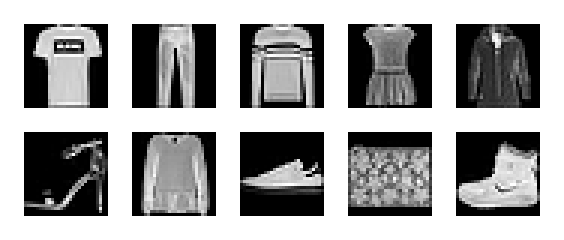

In [4]:
gallery_gap = 8
gallery = fill(RGB{N0f8}(1, 1, 1), 2*28 + 3*gallery_gap, 5*28 + 6*gallery_gap)
for label in 0:9
    image = sample_images[label + 1]
    row_group, column_group = label ÷ 5, label % 5
    y0 = gallery_gap + row_group*(28 + gallery_gap)
    x0 = gallery_gap + column_group*(28 + gallery_gap)
    for row in 1:28, column in 1:28
        value = N0f8(Float32(image[row, column]) / 255f0)
        gallery[y0 + row, x0 + column] = RGB{N0f8}(value, value, value)
    end
end
gallery = repeat(gallery; inner=(3, 3))
PNGFiles.save(joinpath(output_dir, "class_gallery.png"), gallery)
display(Markdown.parse("Mỗi ô là ảnh đại diện của một lớp; thứ tự theo danh sách nhãn ở trên."))
show_demo_image(joinpath(output_dir, "class_gallery.png"); alt="Ảnh đại diện của 10 lớp Fashion-MNIST")

## 2. So sánh kích thước vùng ảnh

Bảng dưới đây tóm tắt khảo sát đã lưu trong [tài liệu lựa chọn tiền xử lý](../../docs/UD2/TC_plan.md). Ở tỷ lệ loại vùng gần nhau, lưới 4×4 làm mất ít năng lượng gradient hơn cấu hình 7×7 đối chứng. Đây là bằng chứng về việc giữ cấu trúc cục bộ, không phải phép đo trực tiếp chất lượng phân cụm.

| Kích thước vùng | Tỷ lệ loại vùng | Gradient mất đi |
|---|---:|---:|
| 4×4 | khoảng 39,3% | 5,92% |
| 7×7 | khoảng 39,3% | 14,00% |

Hình dưới đây dùng cùng 10 ảnh mẫu. Mỗi hàng là một lớp; cột trái dùng patch 4×4, cột phải dùng patch 7×7. Mỗi lưới phủ kín ảnh 28×28, không chồng lấp.

Rows from top: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot


In each row: patch 4×4 on the left; patch 7×7 on the right.


So sánh lưới patch 4×4 và 7×7 trên 10 ảnh thuộc 10 lớp
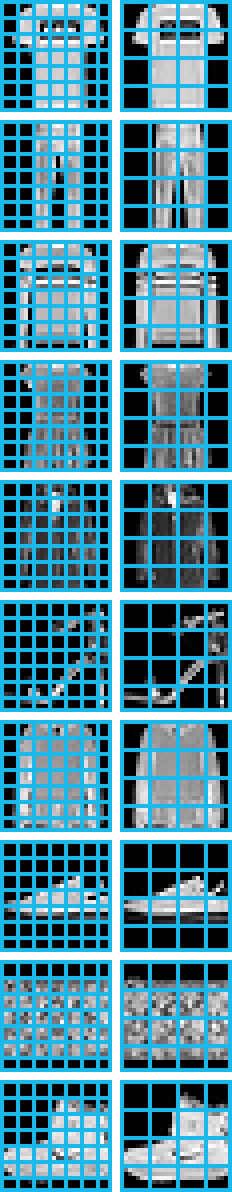

In [5]:
function patch_grid(image, patch_size)
    panel = Matrix{RGB{N0f8}}(undef, 28, 28)
    for row in 1:28, column in 1:28
        gray = N0f8(Float32(image[row, column]) / 255f0)
        panel[row, column] = RGB{N0f8}(gray, gray, gray)
    end
    line = RGB{N0f8}(0.10, 0.72, 0.92)
    for boundary in 1:patch_size:28
        panel[boundary, :] .= line
        panel[:, boundary] .= line
    end
    panel[end, :] .= line
    panel[:, end] .= line
    return repeat(panel; inner=(4, 4))
end

function stack_image_rows(rows; gap=8)
    height, width = size(first(rows))
    canvas = fill(RGB{N0f8}(1,1,1), height*length(rows) + gap*(length(rows)-1), width)
    for row_number in eachindex(rows)
        row = rows[row_number]
        size(row) == (height, width) || error("Montage rows must have equal dimensions")
        y0 = 1 + (row_number-1)*(height+gap)
        canvas[y0:y0+height-1, :] .= row
    end
    return canvas
end

row_gap = 8
patch_rows = Matrix{RGB{N0f8}}[]
for image in sample_images
    panel_4 = patch_grid(image, 4)
    panel_7 = patch_grid(image, 7)
    gap = fill(RGB{N0f8}(1,1,1), size(panel_4,1), 8)
    push!(patch_rows, hcat(panel_4, gap, panel_7))
end
comparison = stack_image_rows(patch_rows; gap=row_gap)
PNGFiles.save(joinpath(output_dir, "patch_size_comparison.png"), comparison)
println("Rows from top: ", join(FASHION_CLASSES, ", "))
println("In each row: patch 4×4 on the left; patch 7×7 on the right.")
show_demo_image(joinpath(output_dir, "patch_size_comparison.png"); alt="So sánh lưới patch 4×4 và 7×7 trên 10 ảnh thuộc 10 lớp")

## 3. So sánh cách lọc nền

Cấu hình phát hành giữ vùng nếu có ít nhất một pixel **lớn hơn 29**. Các tỷ lệ trong bảng là số liệu khảo sát toàn bộ 70.000 ảnh đã lưu trong tài liệu; hình phía dưới minh họa cách các bộ lọc đánh dấu 49 vùng trên cùng 10 ảnh mẫu, mỗi hàng tương ứng một lớp.

| Bộ lọc | Vùng bị loại | Gradient mất đi | Ảnh không còn vùng |
|---|---:|---:|---:|
| Không lọc | 0% | 0% | 0 |
| Mức xám > 10 | 36,43% | 3,78% | 0 |
| **Mức xám > 29** | **37,50%** | **4,41%** | **0** |
| Ngưỡng Otsu 97 | 43,30% | 8,90% | 0 |
| Mức xám > 29 và tỷ lệ pixel vượt ngưỡng > 6,25% | 39,30% | 5,92% | 0 |

Trong hình, mỗi hàng là một lớp và mỗi cột là một quy tắc lọc; xanh nghĩa là giữ, đỏ nghĩa là loại. Riêng hàng cuối, tỷ lệ pixel được tính trong từng patch 4×4; các số liệu hình không thay thế tỷ lệ khảo sát toàn bộ tập ảnh.

Rows from top: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot


Columns: Không lọc | Có pixel > 10 | Có pixel > 29 | Otsu: có pixel > 97 | >29 và tỷ lệ > 6,25%


Năm quy tắc lọc nền được so sánh trên 10 ảnh thuộc 10 lớp
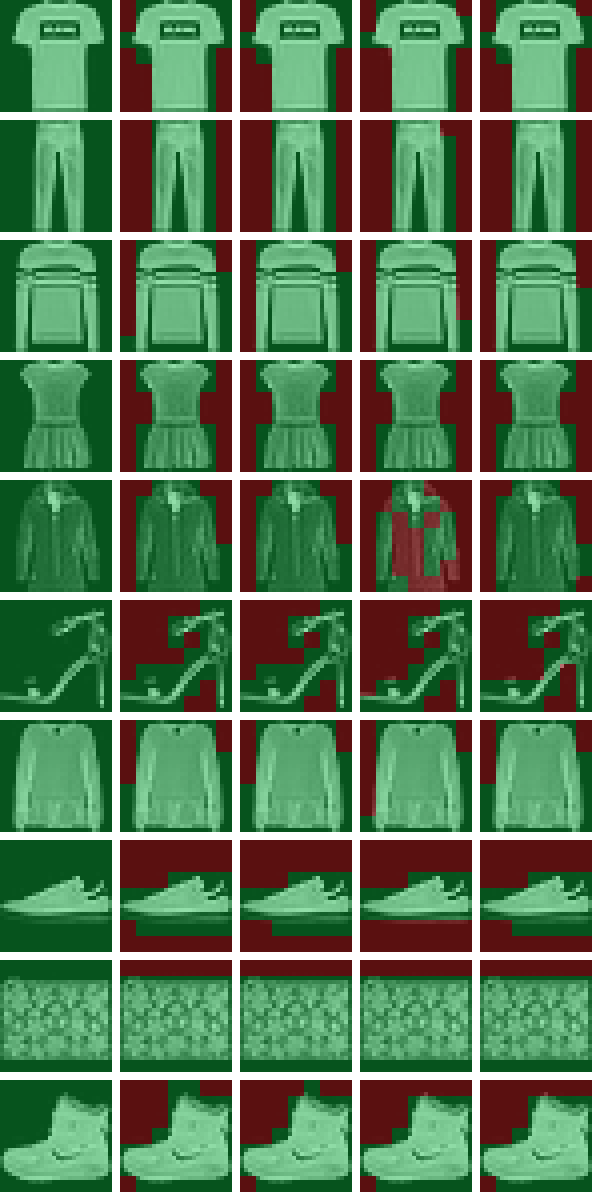

In [6]:
function filtered_patch_panel(image, keep_patch)
    panel = Matrix{RGB{N0f8}}(undef, 28, 28)
    for patch_row in 1:7, patch_col in 1:7
        y0, x0 = (patch_row-1)*4+1, (patch_col-1)*4+1
        values = image[y0:y0+3, x0:x0+3]
        keep = keep_patch(values)
        tint = keep ? (0.05f0, 0.72f0, 0.25f0) : (0.78f0, 0.14f0, 0.14f0)
        for row in y0:y0+3, column in x0:x0+3
            gray = Float32(image[row, column]) / 255f0
            panel[row, column] = RGB{N0f8}(0.55f0*gray + 0.45f0*tint[1],
                0.55f0*gray + 0.45f0*tint[2], 0.55f0*gray + 0.45f0*tint[3])
        end
    end
    return repeat(panel; inner=(4, 4))
end

filters = [
    ("Không lọc", _ -> true),
    ("Có pixel > 10", p -> any(>(10), p)),
    ("Có pixel > 29", p -> any(>(29), p)),
    ("Otsu: có pixel > 97", p -> any(>(97), p)),
    (">29 và tỷ lệ > 6,25%", p -> count(>(29), p)/length(p) > 0.0625),
]
filter_rows = Matrix{RGB{N0f8}}[]
for image in sample_images
    panels = [filtered_patch_panel(image, rule) for (_, rule) in filters]
    spacer = fill(RGB{N0f8}(1,1,1), size(first(panels),1), 8)
    push!(filter_rows, reduce((left, right) -> hcat(left, spacer, right), panels))
end
filter_comparison = stack_image_rows(filter_rows; gap=8)
PNGFiles.save(joinpath(output_dir, "filter_comparison.png"), filter_comparison)
println("Rows from top: ", join(FASHION_CLASSES, ", "))
println("Columns: ", join(first.(filters), " | "))
show_demo_image(joinpath(output_dir, "filter_comparison.png"); alt="Năm quy tắc lọc nền được so sánh trên 10 ảnh thuộc 10 lớp")

## 4. Kiểm tra descriptor dùng cho notebook 02

FashionTC xử lý lần lượt cả 10 ảnh mẫu, mỗi ảnh thành 49 patch không chồng lấp kích thước 4×4. `make_descriptors` giữ thứ tự cột của Julia khi trải phẳng, chuyển pixel UInt8 sang Float32 trong [0, 1] bằng cách chia 255, và loại nhãn lớp cùng tọa độ khỏi descriptor.

Rows from top: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot


Patches retained per sample: T-shirt/top=36, Trouser=28, Pullover=40, Dress=31, Coat=36, Sandal=29, Shirt=43, Sneaker=23, Bag=42, Ankle boot=34
FashionTC produced 342 descriptors with 16 values each across ten images.
First descriptor, from T-shirt/top

: [0.0, 0.0, 0.0, 0.0, 0.0039, 0.0, 0.0549, 0.7373, 0.0, 0.0, 0.6902, 0.8588, 0.0, 0.1922, 0.8706, 0.7843]


FashionTC lọc patch trên 10 ảnh; mỗi hàng là một lớp, xanh được giữ và đỏ bị loại
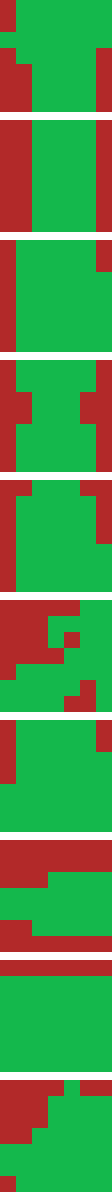

Patch 4×4 được giữ từ ảnh mẫu lớp đầu tiên, phóng lớn
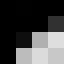

Output: /tmp/fashion-demo-output-dbadabc4/image-exploration/fashion_22602704639306

In [7]:
image_stack = cat(sample_images...; dims=3)
patches, patch_index = FashionTC.extract_patches(image_stack, sample_ids; patch_size=4)
descriptors, retained_index, retained_positions = FashionTC.make_descriptors(
    patches, patch_index, 29; alpha=0.0
)
isempty(descriptors) && error("The selected samples have no retained patches")
kept = Set(retained_positions)
mask_rows = Matrix{RGB{N0f8}}[]
for image_number in eachindex(sample_images)
    mask = fill(RGB{N0f8}(0.12, 0.12, 0.12), 28, 28)
    for patch_number in eachindex(patches)
        item = patch_index[patch_number]
        item.image_id == sample_ids[image_number] || continue
        y0, x0 = (item.patch_row - 1)*4 + 1, (item.patch_col - 1)*4 + 1
        color = patch_number in kept ? RGB{N0f8}(0.08, 0.72, 0.30) : RGB{N0f8}(0.70, 0.16, 0.16)
        mask[y0:y0+3, x0:x0+3] .= color
    end
    push!(mask_rows, repeat(mask; inner=(4, 4)))
end
mask_montage = stack_image_rows(mask_rows; gap=8)
retained_counts = [count(item -> item.image_id == image_id, retained_index) for image_id in sample_ids]
first_retained_position = findfirst(item -> item.image_id == sample_ids[1], retained_index)
isnothing(first_retained_position) && error("The first sample has no retained patch")
first_retained = retained_index[first_retained_position]
patch_y, patch_x = (first_retained.patch_row - 1)*4 + 1, (first_retained.patch_col - 1)*4 + 1
example_patch = sample_images[1][patch_y:patch_y+3, patch_x:patch_x+3]
PNGFiles.save(joinpath(output_dir, "patch_filter_mask.png"), mask_montage)
PNGFiles.save(joinpath(output_dir, "retained_patch.png"), repeat(example_patch; inner=(16, 16)))
println("Rows from top: ", join(FASHION_CLASSES, ", "))
println("Patches retained per sample: ", join(["$(FASHION_CLASSES[i])=$(retained_counts[i])" for i in eachindex(sample_ids)], ", "))
println("FashionTC produced ", size(descriptors,2), " descriptors with 16 values each across ten images.")
println("First descriptor, from ", FASHION_CLASSES[1], ": [", join(round.(descriptors[:,first_retained_position]; digits=4), ", "), "]")
show_demo_image(joinpath(output_dir, "patch_filter_mask.png"); alt="FashionTC lọc patch trên 10 ảnh; mỗi hàng là một lớp, xanh được giữ và đỏ bị loại")
show_demo_image(joinpath(output_dir, "retained_patch.png"); alt="Patch 4×4 được giữ từ ảnh mẫu lớp đầu tiên, phóng lớn")
open(joinpath(output_dir, "image_eda_summary.md"), "w") do io
    println(io, "Mã lượt: ", run_id)
    println(io, "Manifest dữ liệu: ", loaded.manifest_path)
    println(io, "Mười ảnh mẫu theo lớp: ", join(["$(FASHION_CLASSES[i])=$(sample_ids[i])" for i in eachindex(sample_ids)], "; "))
    println(io, "Descriptor: 16 chiều; tổng số patch giữ: ", size(descriptors,2), ".")
end
println("Output: ", output_dir)